## Prioritization of Pending Delivery Tasks (Flag 16)

### Dataset Overview

One courier route linking 24 tasks accepted before departure, with candidate age and proximity ranks reconstructed at every completion decision.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Investigate how the courier prioritizes pending delivery tasks.

Role: Last-mile delivery operations analyst


Category: pending-task age, destination proximity, and backlog-dependent priority


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Does the courier consistently complete pending tasks in acceptance order?

#### Analysis action

Compare acceptance and completion ranks and count pairwise order inversions.

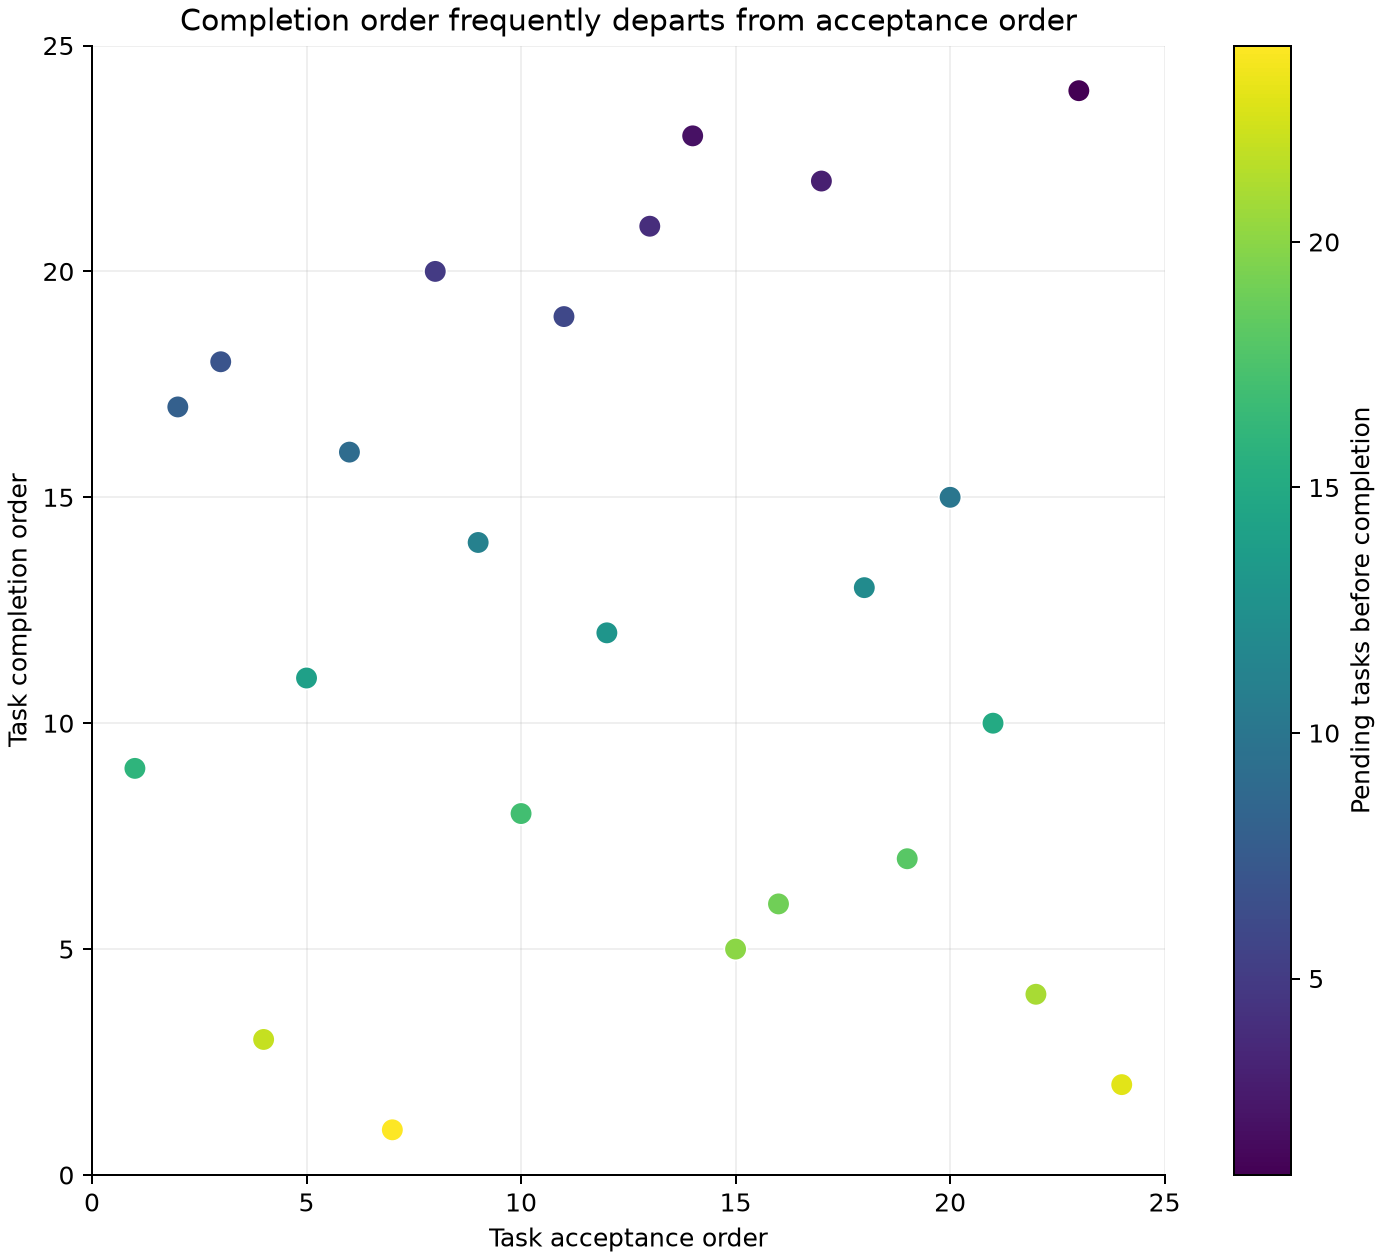

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


def acceptance_completion_plot(df):
    fig, ax = plt.subplots(figsize=(7.7, 7), constrained_layout=True)
    points = ax.scatter(
        df.acceptance_order,
        df.completion_order,
        c=df.pending_count_before_completion,
        cmap="viridis",
        s=82,
        edgecolor="white",
        linewidth=0.7,
    )
    fig.colorbar(points, ax=ax, label="Pending tasks before completion")
    ax.set(
        xlabel="Task acceptance order",
        ylabel="Task completion order",
        title="Completion order frequently departs from acceptance order",
        xlim=(0, len(df) + 1),
        ylim=(0, len(df) + 1),
    )
    ax.set_axisbelow(True)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    print(df[["acceptance_order", "completion_order"]].corr(method="spearman"))


acceptance_completion_plot(df)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/acceptance_vs_completion_order.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "task_acceptance_and_completion_order",
  "insight_type": "overall_pattern",
  "insight": "The courier does not consistently complete pending tasks in the order in which they were accepted.",
  "insight_value": {
    "tasks": 24,
    "pairwise_order_inversions": 141,
    "spearman_acceptance_completion": -0.051
  },
  "plot": {
    "plot_type": "acceptance_completion_order_scatter",
    "title": "Acceptance and Completion Order",
    "file": "visualizations/acceptance_vs_completion_order.png",
    "description": "Task acceptance and completion ranks are plotted without a reference or fitted line; color indicates the pending-task count."
  },
  "question": "Does the courier consistently complete pending tasks in acceptance order?",
  "actionable_insight": "Compare acceptance and completion ranks and count pairwise order inversions.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\ndef acceptance_completion_plot(df):\n    fig, ax = plt.subplots(figsize=(7.7, 7), constrained_layout=True)\n    points = ax.scatter(df.acceptance_order, df.completion_order,\n        c=df.pending_count_before_completion, cmap='viridis', s=82,\n        edgecolor='white', linewidth=.7)\n    fig.colorbar(points, ax=ax, label='Pending tasks before completion')\n    ax.set(xlabel='Task acceptance order', ylabel='Task completion order',\n        title='Completion order frequently departs from acceptance order',\n        xlim=(0, len(df)+1), ylim=(0, len(df)+1))\n    ax.set_axisbelow(True)\n    ax.grid(alpha=.2)\n    ax.spines[['top', 'right']].set_visible(False)\n    print(df[['acceptance_order', 'completion_order']].corr(method='spearman'))\n\nacceptance_completion_plot(df)\nplt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "completion_time",
    "task_id"
  ]
}

### **Question 2**: When many tasks are pending, is selection more closely aligned with task age or destination proximity?

#### Analysis action

At every completion decision with at least nine pending tasks, rank all candidates by age and current distance, then compare the selected ranks.

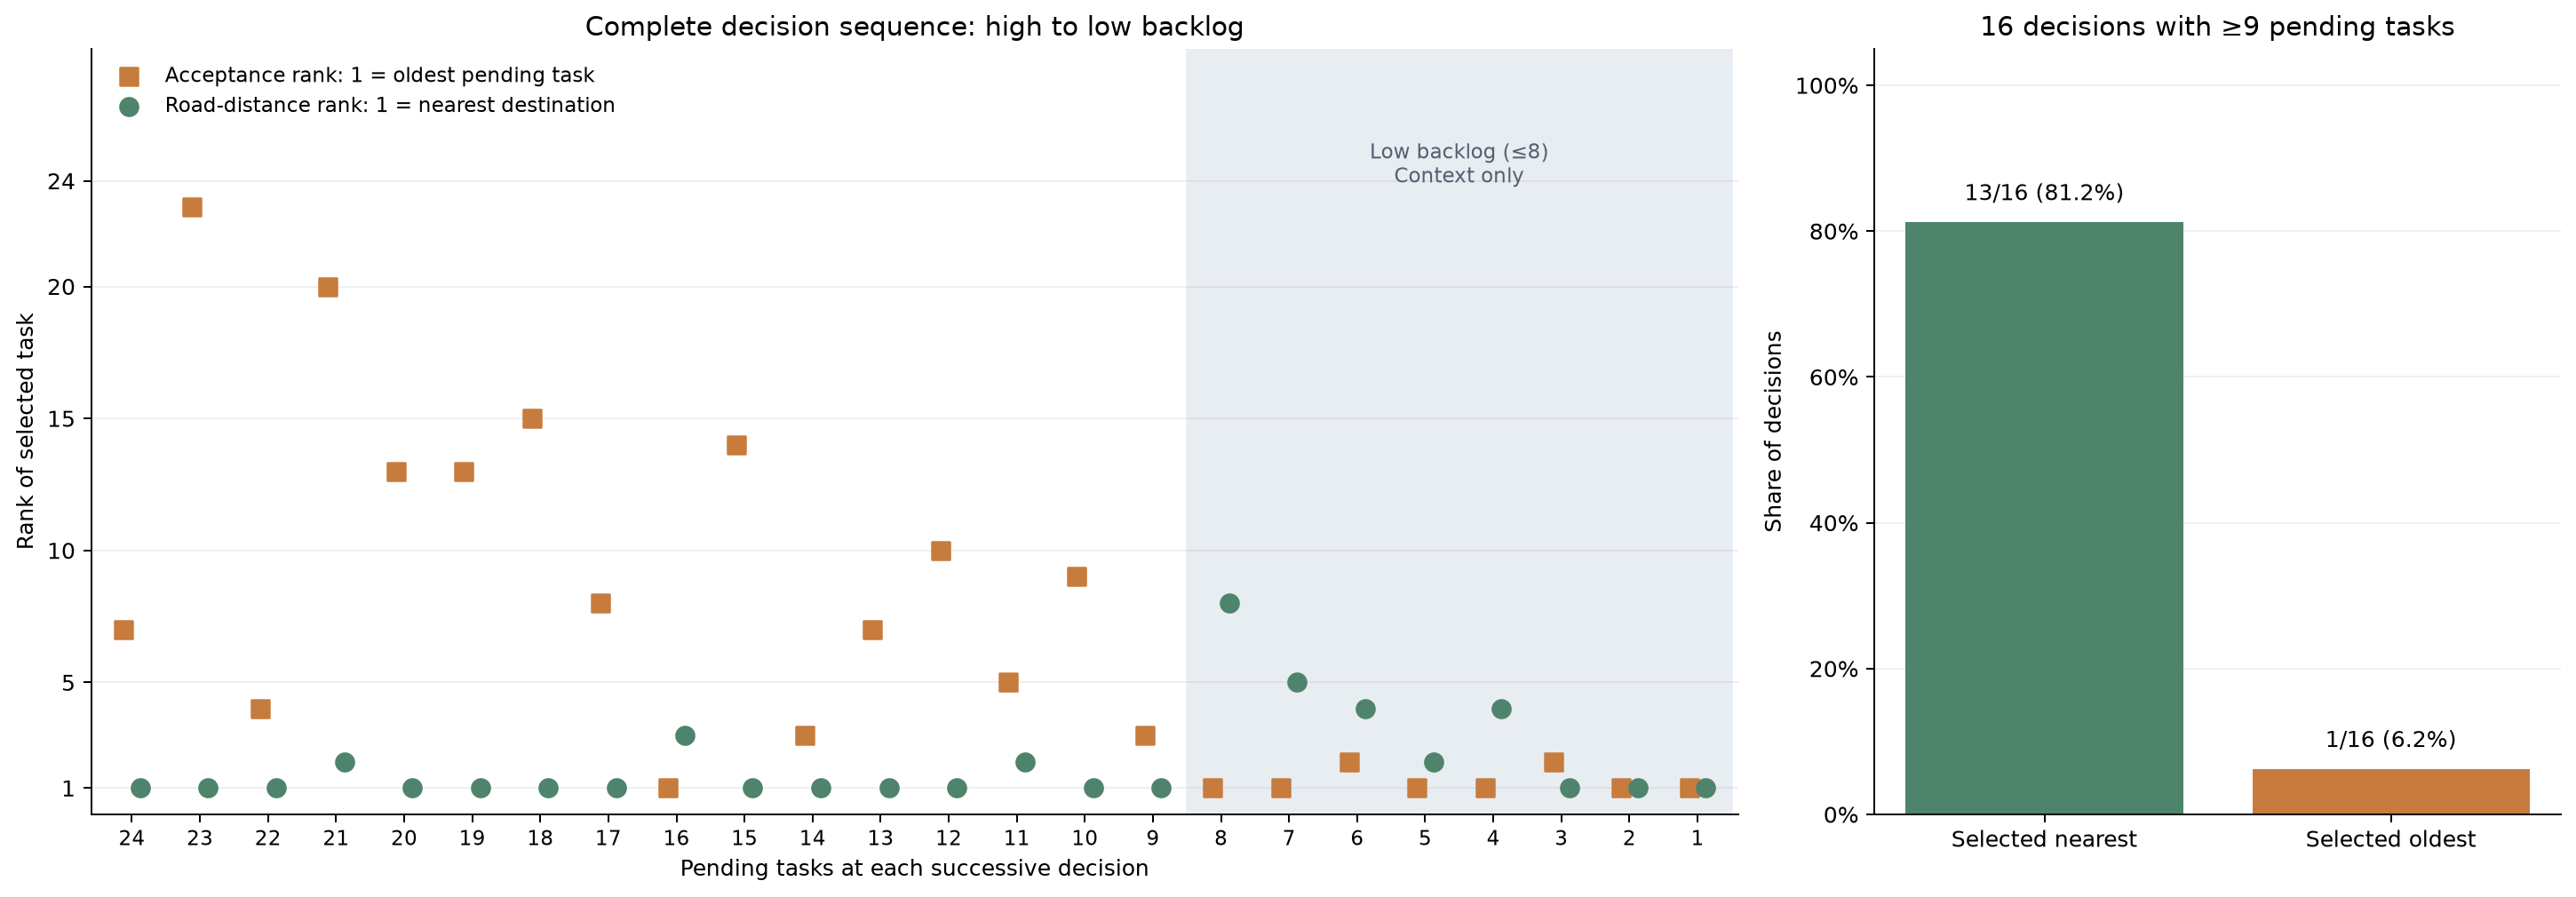

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def priority_plot(df, index):
    d = df.sort_values("completion_order").copy()
    if index == 1:
        q = d[d.pending_count_before_completion >= 9]
        fig, axes = plt.subplots(
            1,
            2,
            figsize=(16, 5.5),
            constrained_layout=True,
            gridspec_kw={"width_ratios": [2.4, 1]},
        )
        x = np.arange(len(d))
        low_positions = x[d.pending_count_before_completion.to_numpy() < 9]
        if len(low_positions):
            axes[0].axvspan(
                low_positions.min() - 0.5,
                low_positions.max() + 0.5,
                color="#e8edf2",
                zorder=0,
            )
            axes[0].text(
                float(low_positions.mean()),
                25.5,
                "Low backlog (≤8)\nContext only",
                ha="center",
                va="top",
                fontsize=9,
                color="#536170",
            )
        axes[0].scatter(
            x - 0.12,
            d.acceptance_rank_among_pending,
            color="#c77c3d",
            marker="s",
            s=65,
            label="Acceptance rank: 1 = oldest pending task",
        )
        axes[0].scatter(
            x + 0.12,
            d.proximity_rank_among_pending,
            color="#4f846c",
            s=65,
            label="Road-distance rank: 1 = nearest destination",
        )
        axes[0].set(
            xticks=x,
            xticklabels=d.pending_count_before_completion,
            xlabel="Pending tasks at each successive decision",
            ylabel="Rank of selected task",
            title="Complete decision sequence: high to low backlog",
            xlim=(-0.6, len(d) - 0.4),
            ylim=(0, 29),
            yticks=[1, 5, 10, 15, 20, 24],
        )
        axes[0].tick_params(axis="x", labelsize=9)
        axes[0].legend(loc="upper left", frameon=False, fontsize=9)
        rates = [
            (q.proximity_rank_among_pending == 1).mean(),
            (q.acceptance_rank_among_pending == 1).mean(),
        ]
        counts = [
            int((q.proximity_rank_among_pending == 1).sum()),
            int((q.acceptance_rank_among_pending == 1).sum()),
        ]
        axes[1].bar(
            ["Selected nearest", "Selected oldest"], rates, color=["#4f846c", "#c77c3d"]
        )
        for i, rate in enumerate(rates):
            axes[1].text(
                i, rate + 0.03, f"{counts[i]}/{len(q)} ({rate:.1%})", ha="center"
            )
        axes[1].set(
            ylim=(0, 1.05),
            ylabel="Share of decisions",
            title=f"{len(q)} decisions with ≥9 pending tasks",
        )
        axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
        evidence = dict(
            high_age_median=float(q.acceptance_rank_among_pending.median()),
            high_proximity_median=float(q.proximity_rank_among_pending.median()),
            high_pending_decisions=len(q),
            nearest_selected_count=counts[0],
            oldest_selected_count=counts[1],
        )
    else:
        # One remaining task offers no prioritization choice; exclude it.
        d = d[d.pending_count_before_completion > 1].copy()
        d["normalized_age_rank"] = (d.acceptance_rank_among_pending - 1) / (
            d.pending_count_before_completion - 1
        )
        labels = ["Low (2–8)", "Medium (9–16)", "High (17–24)"]
        d["band"] = pd.cut(
            d.pending_count_before_completion, [1, 8, 16, 24], labels=labels
        )
        stats = d.groupby("band", observed=True).normalized_age_rank.agg(
            ["mean", "count"]
        )
        fig, axes = plt.subplots(1, 2, figsize=(12.7, 5.4), constrained_layout=True)
        axes[0].scatter(
            d.pending_count_before_completion,
            d.normalized_age_rank,
            s=65,
            color="#3976a8",
            edgecolor="white",
        )
        axes[0].set(
            xlabel="Pending tasks before completion",
            ylabel="Normalized acceptance rank (0 = oldest, 1 = newest)",
            title="Lower backlog favors earlier-accepted tasks",
            ylim=(-0.03, 1.08),
        )
        axes[1].bar(labels, stats["mean"], color=["#4f846c", "#3976a8", "#c77c3d"])
        for i, row in enumerate(stats.itertuples()):
            axes[1].text(
                i, row.mean + 0.025, f"{row.mean:.3f}\nn={row.count}", ha="center"
            )
        axes[1].set(
            ylabel="Mean normalized acceptance rank (lower = older)",
            title="Backlog groups; single-task case excluded",
            ylim=(0, 1),
        )
        evidence = dict(
            mean_normalized_age_rank_by_backlog=stats["mean"].round(3).to_dict(),
            high_minus_medium_mean=round(
                float(stats.loc[labels[2], "mean"] - stats.loc[labels[1], "mean"]), 3
            ),
            low_pending_age_rank_median=float(
                d[
                    d.pending_count_before_completion <= 8
                ].acceptance_rank_among_pending.median()
            ),
            excluded_single_task_decisions=1,
        )
    for ax in axes:
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)
    print(evidence)
    return evidence


evidence = priority_plot(df, 1)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/high_pending_proximity_priority.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "high_backlog_selected_task_ranks",
  "insight_type": "factor_relationship",
  "insight": "When many tasks are pending at the same time, completion order is more strongly organized by destination proximity than by task age.",
  "insight_value": {
    "high_age_median": 8.5,
    "high_proximity_median": 1.0,
    "high_pending_decisions": 16,
    "nearest_selected_count": 13,
    "oldest_selected_count": 1
  },
  "plot": {
    "plot_type": "decision_rank_comparison_and_first_choice_rates",
    "title": "High-backlog Spatial Priority",
    "file": "visualizations/high_pending_proximity_priority.png",
    "description": "Left: all 24 decisions with every pending-count tick from 24 to 1; shaded low-backlog decisions provide context. Right: nearest and oldest selection rates use only the 16 decisions with at least nine pending tasks."
  },
  "question": "When many tasks are pending, is selection more closely aligned with task age or destination proximity?",
  "actionable_insight": "At every completion decision with at least nine pending tasks, rank all candidates by age and current distance, then compare the selected ranks.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef priority_plot(df, index):\n    d = df.sort_values('completion_order').copy()\n    if index == 1:\n        q = d[d.pending_count_before_completion >= 9]\n        fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), constrained_layout=True,\n            gridspec_kw={'width_ratios': [2.4, 1]})\n        x = np.arange(len(d))\n        low_positions = x[d.pending_count_before_completion.to_numpy() < 9]\n        if len(low_positions):\n            axes[0].axvspan(low_positions.min()-.5, low_positions.max()+.5,\n                color='#e8edf2', zorder=0)\n            axes[0].text(float(low_positions.mean()), 25.5, 'Low backlog (≤8)\\nContext only',\n                ha='center', va='top', fontsize=9, color='#536170')\n        axes[0].scatter(x-.12, d.acceptance_rank_among_pending, color='#c77c3d',\n            marker='s', s=65, label='Acceptance rank: 1 = oldest pending task')\n        axes[0].scatter(x+.12, d.proximity_rank_among_pending, color='#4f846c',\n            s=65, label='Road-distance rank: 1 = nearest destination')\n        axes[0].set(xticks=x, xticklabels=d.pending_count_before_completion,\n            xlabel='Pending tasks at each successive decision', ylabel='Rank of selected task',\n            title='Complete decision sequence: high to low backlog', xlim=(-.6,len(d)-.4),\n            ylim=(0, 29), yticks=[1, 5, 10, 15, 20, 24])\n        axes[0].tick_params(axis='x', labelsize=9)\n        axes[0].legend(loc='upper left', frameon=False, fontsize=9)\n        rates = [(q.proximity_rank_among_pending == 1).mean(),\n                 (q.acceptance_rank_among_pending == 1).mean()]\n        counts = [int((q.proximity_rank_among_pending == 1).sum()),\n                  int((q.acceptance_rank_among_pending == 1).sum())]\n        axes[1].bar(['Selected nearest', 'Selected oldest'], rates, color=['#4f846c', '#c77c3d'])\n        for i, rate in enumerate(rates):\n            axes[1].text(i, rate+.03, f'{counts[i]}/{len(q)} ({rate:.1%})', ha='center')\n        axes[1].set(ylim=(0, 1.05), ylabel='Share of decisions', title=f'{len(q)} decisions with ≥9 pending tasks')\n        axes[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')\n        evidence = dict(high_age_median=float(q.acceptance_rank_among_pending.median()),\n            high_proximity_median=float(q.proximity_rank_among_pending.median()),\n            high_pending_decisions=len(q), nearest_selected_count=counts[0], oldest_selected_count=counts[1])\n    else:\n        # One remaining task offers no prioritization choice; exclude it.\n        d = d[d.pending_count_before_completion > 1].copy()\n        d['normalized_age_rank'] = (d.acceptance_rank_among_pending-1)/(d.pending_count_before_completion-1)\n        labels = ['Low (2–8)', 'Medium (9–16)', 'High (17–24)']\n        d['band'] = pd.cut(d.pending_count_before_completion, [1, 8, 16, 24], labels=labels)\n        stats = d.groupby('band', observed=True).normalized_age_rank.agg(['mean', 'count'])\n        fig, axes = plt.subplots(1, 2, figsize=(12.7, 5.4), constrained_layout=True)\n        axes[0].scatter(d.pending_count_before_completion, d.normalized_age_rank,\n            s=65, color='#3976a8', edgecolor='white')\n        axes[0].set(xlabel='Pending tasks before completion',\n            ylabel='Normalized acceptance rank (0 = oldest, 1 = newest)',\n            title='Lower backlog favors earlier-accepted tasks', ylim=(-.03, 1.08))\n        axes[1].bar(labels, stats['mean'], color=['#4f846c', '#3976a8', '#c77c3d'])\n        for i, row in enumerate(stats.itertuples()):\n            axes[1].text(i, row.mean+.025, f'{row.mean:.3f}\\nn={row.count}', ha='center')\n        axes[1].set(ylabel='Mean normalized acceptance rank (lower = older)',\n            title='Backlog groups; single-task case excluded', ylim=(0, 1))\n        evidence = dict(mean_normalized_age_rank_by_backlog=stats['mean'].round(3).to_dict(),\n            high_minus_medium_mean=round(float(stats.loc[labels[2], 'mean']-stats.loc[labels[1], 'mean']), 3),\n            low_pending_age_rank_median=float(d[d.pending_count_before_completion <= 8].acceptance_rank_among_pending.median()),\n            excluded_single_task_decisions=1)\n    for ax in axes:\n        ax.set_axisbelow(True); ax.grid(axis='y', alpha=.2)\n        ax.spines[['top', 'right']].set_visible(False)\n    print(evidence)\n    return evidence\n\nevidence = priority_plot(df, 1)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "completion_time",
    "delivery_position",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### **Question 3**: How does alignment with acceptance order change as the pending queue becomes smaller?

#### Analysis action

Exclude decisions with only one pending task, normalize the selected acceptance rank as (rank-1)/(pending count-1), and compare backlog-band means.

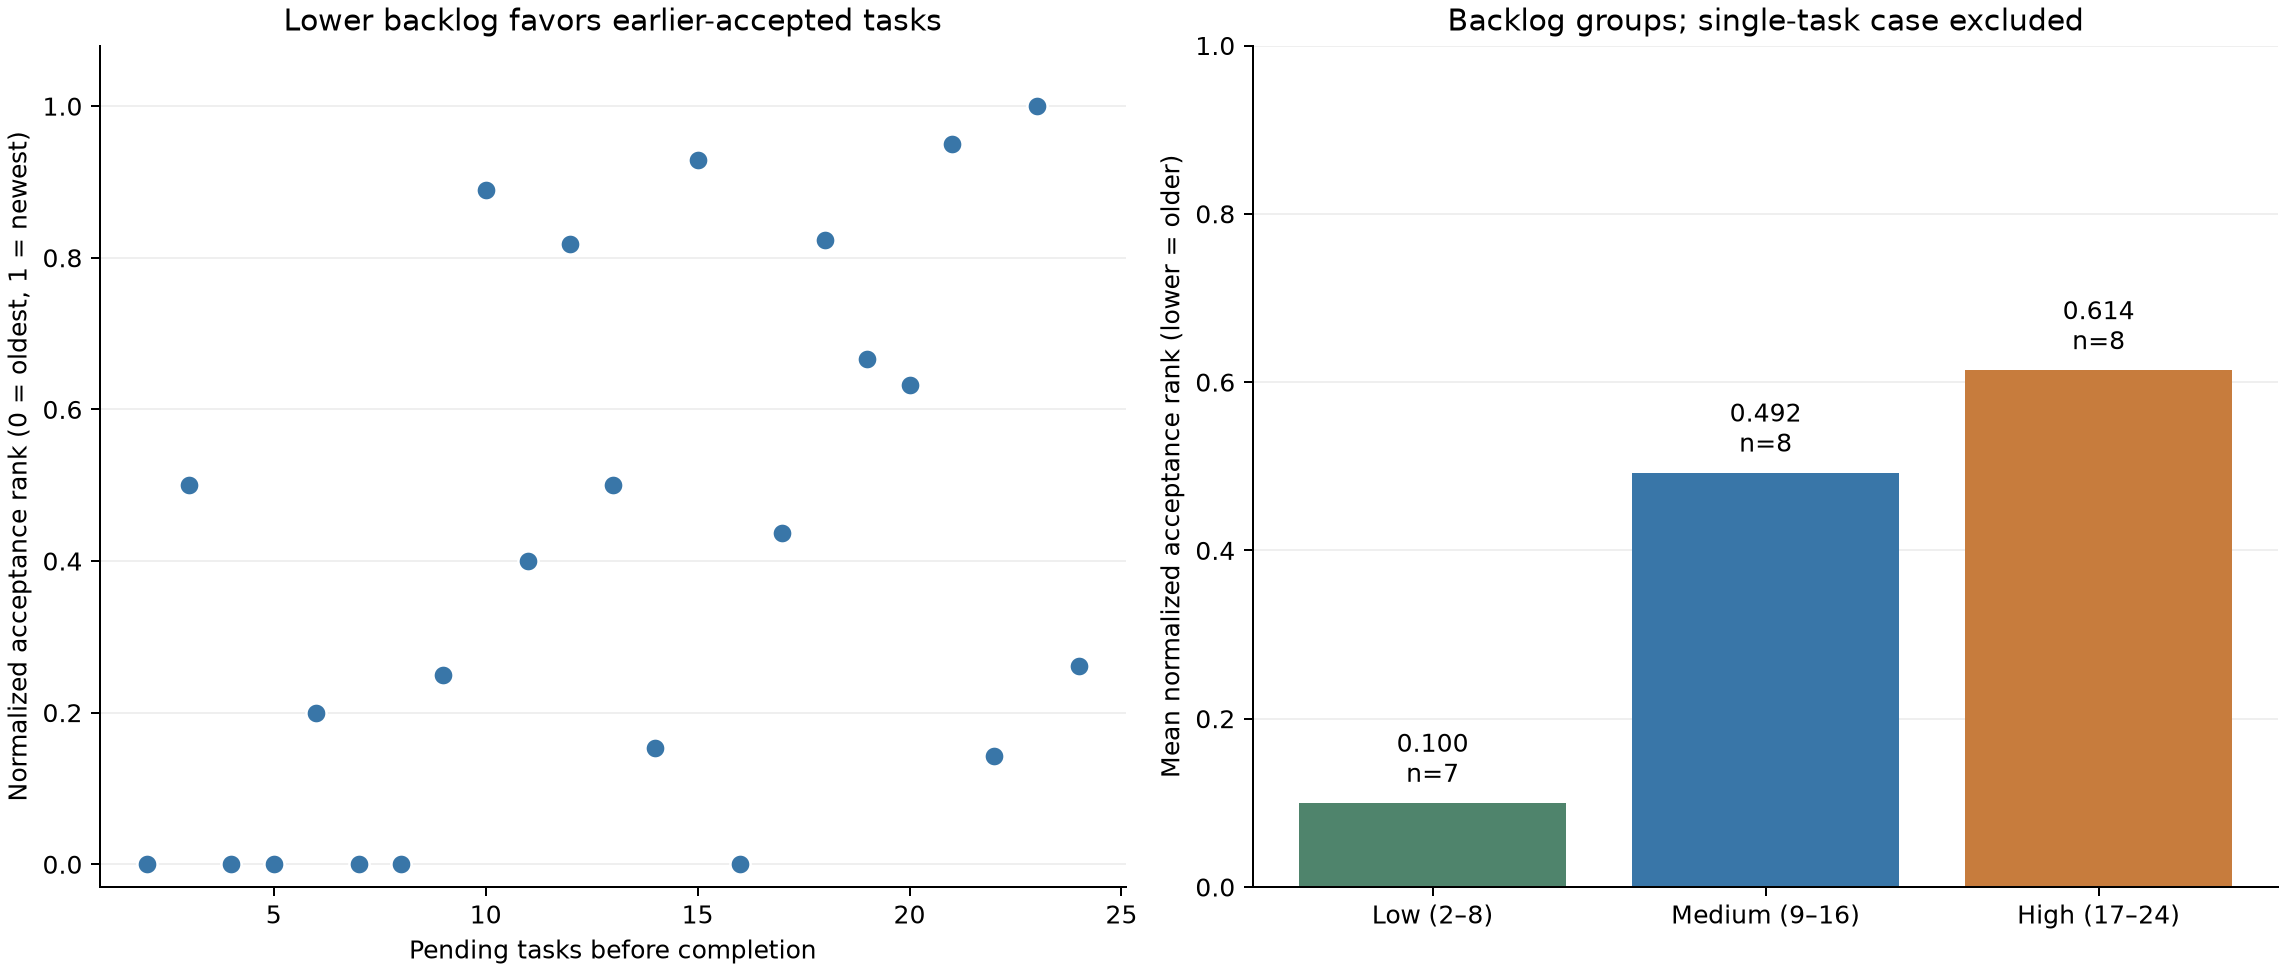

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def priority_plot(df, index):
    d = df.sort_values("completion_order").copy()
    if index == 1:
        q = d[d.pending_count_before_completion >= 9]
        fig, axes = plt.subplots(
            1,
            2,
            figsize=(13, 5.5),
            constrained_layout=True,
            gridspec_kw={"width_ratios": [1.7, 1]},
        )
        x = np.arange(len(q))
        axes[0].scatter(
            x - 0.12,
            q.acceptance_rank_among_pending,
            color="#c77c3d",
            marker="s",
            s=65,
            label="Acceptance rank: 1 = oldest pending task",
        )
        axes[0].scatter(
            x + 0.12,
            q.proximity_rank_among_pending,
            color="#4f846c",
            s=65,
            label="Road-distance rank: 1 = nearest destination",
        )
        axes[0].set(
            xticks=x,
            xticklabels=q.pending_count_before_completion,
            xlabel="Pending tasks at each successive decision",
            ylabel="Rank of selected task",
            title="The selected task is usually nearest, not oldest",
            ylim=(0, 29),
            yticks=[1, 5, 10, 15, 20, 24],
        )
        axes[0].legend(loc="upper left", frameon=False, fontsize=9)
        rates = [
            (q.proximity_rank_among_pending == 1).mean(),
            (q.acceptance_rank_among_pending == 1).mean(),
        ]
        counts = [
            int((q.proximity_rank_among_pending == 1).sum()),
            int((q.acceptance_rank_among_pending == 1).sum()),
        ]
        axes[1].bar(
            ["Selected nearest", "Selected oldest"], rates, color=["#4f846c", "#c77c3d"]
        )
        for i, rate in enumerate(rates):
            axes[1].text(
                i, rate + 0.03, f"{counts[i]}/{len(q)} ({rate:.1%})", ha="center"
            )
        axes[1].set(
            ylim=(0, 1.05),
            ylabel="Share of decisions",
            title=f"{len(q)} decisions with ≥9 pending tasks",
        )
        axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
        evidence = dict(
            high_age_median=float(q.acceptance_rank_among_pending.median()),
            high_proximity_median=float(q.proximity_rank_among_pending.median()),
            high_pending_decisions=len(q),
            nearest_selected_count=counts[0],
            oldest_selected_count=counts[1],
        )
    else:
        # One remaining task offers no prioritization choice; exclude it.
        d = d[d.pending_count_before_completion > 1].copy()
        d["normalized_age_rank"] = (d.acceptance_rank_among_pending - 1) / (
            d.pending_count_before_completion - 1
        )
        labels = ["Low (2–8)", "Medium (9–16)", "High (17–24)"]
        d["band"] = pd.cut(
            d.pending_count_before_completion, [1, 8, 16, 24], labels=labels
        )
        stats = d.groupby("band", observed=True).normalized_age_rank.agg(
            ["mean", "count"]
        )
        fig, axes = plt.subplots(1, 2, figsize=(12.7, 5.4), constrained_layout=True)
        axes[0].scatter(
            d.pending_count_before_completion,
            d.normalized_age_rank,
            s=65,
            color="#3976a8",
            edgecolor="white",
        )
        axes[0].set(
            xlabel="Pending tasks before completion",
            ylabel="Normalized acceptance rank (0 = oldest, 1 = newest)",
            title="Lower backlog favors earlier-accepted tasks",
            ylim=(-0.03, 1.08),
        )
        axes[1].bar(labels, stats["mean"], color=["#4f846c", "#3976a8", "#c77c3d"])
        for i, row in enumerate(stats.itertuples()):
            axes[1].text(
                i, row.mean + 0.025, f"{row.mean:.3f}\nn={row.count}", ha="center"
            )
        axes[1].set(
            ylabel="Mean normalized acceptance rank (lower = older)",
            title="Backlog groups; single-task case excluded",
            ylim=(0, 1),
        )
        evidence = dict(
            mean_normalized_age_rank_by_backlog=stats["mean"].round(3).to_dict(),
            high_minus_medium_mean=round(
                float(stats.loc[labels[2], "mean"] - stats.loc[labels[1], "mean"]), 3
            ),
            low_pending_age_rank_median=float(
                d[
                    d.pending_count_before_completion <= 8
                ].acceptance_rank_among_pending.median()
            ),
            excluded_single_task_decisions=1,
        )
    for ax in axes:
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)
    print(evidence)
    return evidence


evidence = priority_plot(df, 2)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/pending_count_acceptance_alignment.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "backlog_level_and_acceptance_order_alignment",
  "insight_type": "factor_relationship",
  "insight": "As the number of pending tasks decreases, the courier's completion order becomes more closely aligned with the tasks' acceptance order.",
  "insight_value": {
    "mean_normalized_age_rank_by_backlog": {
      "Low (2–8)": 0.1,
      "Medium (9–16)": 0.492,
      "High (17–24)": 0.614
    },
    "high_minus_medium_mean": 0.122,
    "low_pending_age_rank_median": 1.0,
    "excluded_single_task_decisions": 1
  },
  "plot": {
    "plot_type": "decision_scatter_and_backlog_bands",
    "title": "Backlog and Acceptance-order Alignment",
    "file": "visualizations/pending_count_acceptance_alignment.png",
    "description": "Decision-level normalized acceptance ranks and backlog means; one-task decisions are excluded because no prioritization choice is possible."
  },
  "question": "How does alignment with acceptance order change as the pending queue becomes smaller?",
  "actionable_insight": "Exclude decisions with only one pending task, normalize the selected acceptance rank as (rank-1)/(pending count-1), and compare backlog-band means.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef priority_plot(df, index):\n    d = df.sort_values('completion_order').copy()\n    if index == 1:\n        q = d[d.pending_count_before_completion >= 9]\n        fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True,\n            gridspec_kw={'width_ratios': [1.7, 1]})\n        x = np.arange(len(q))\n        axes[0].scatter(x-.12, q.acceptance_rank_among_pending, color='#c77c3d',\n            marker='s', s=65, label='Acceptance rank: 1 = oldest pending task')\n        axes[0].scatter(x+.12, q.proximity_rank_among_pending, color='#4f846c',\n            s=65, label='Road-distance rank: 1 = nearest destination')\n        axes[0].set(xticks=x, xticklabels=q.pending_count_before_completion,\n            xlabel='Pending tasks at each successive decision', ylabel='Rank of selected task',\n            title='The selected task is usually nearest, not oldest', ylim=(0, 29), yticks=[1, 5, 10, 15, 20, 24])\n        axes[0].legend(loc='upper left', frameon=False, fontsize=9)\n        rates = [(q.proximity_rank_among_pending == 1).mean(),\n                 (q.acceptance_rank_among_pending == 1).mean()]\n        counts = [int((q.proximity_rank_among_pending == 1).sum()),\n                  int((q.acceptance_rank_among_pending == 1).sum())]\n        axes[1].bar(['Selected nearest', 'Selected oldest'], rates, color=['#4f846c', '#c77c3d'])\n        for i, rate in enumerate(rates):\n            axes[1].text(i, rate+.03, f'{counts[i]}/{len(q)} ({rate:.1%})', ha='center')\n        axes[1].set(ylim=(0, 1.05), ylabel='Share of decisions', title=f'{len(q)} decisions with ≥9 pending tasks')\n        axes[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')\n        evidence = dict(high_age_median=float(q.acceptance_rank_among_pending.median()),\n            high_proximity_median=float(q.proximity_rank_among_pending.median()),\n            high_pending_decisions=len(q), nearest_selected_count=counts[0], oldest_selected_count=counts[1])\n    else:\n        # One remaining task offers no prioritization choice; exclude it.\n        d = d[d.pending_count_before_completion > 1].copy()\n        d['normalized_age_rank'] = (d.acceptance_rank_among_pending-1)/(d.pending_count_before_completion-1)\n        labels = ['Low (2–8)', 'Medium (9–16)', 'High (17–24)']\n        d['band'] = pd.cut(d.pending_count_before_completion, [1, 8, 16, 24], labels=labels)\n        stats = d.groupby('band', observed=True).normalized_age_rank.agg(['mean', 'count'])\n        fig, axes = plt.subplots(1, 2, figsize=(12.7, 5.4), constrained_layout=True)\n        axes[0].scatter(d.pending_count_before_completion, d.normalized_age_rank,\n            s=65, color='#3976a8', edgecolor='white')\n        axes[0].set(xlabel='Pending tasks before completion',\n            ylabel='Normalized acceptance rank (0 = oldest, 1 = newest)',\n            title='Lower backlog favors earlier-accepted tasks', ylim=(-.03, 1.08))\n        axes[1].bar(labels, stats['mean'], color=['#4f846c', '#3976a8', '#c77c3d'])\n        for i, row in enumerate(stats.itertuples()):\n            axes[1].text(i, row.mean+.025, f'{row.mean:.3f}\\nn={row.count}', ha='center')\n        axes[1].set(ylabel='Mean normalized acceptance rank (lower = older)',\n            title='Backlog groups; single-task case excluded', ylim=(0, 1))\n        evidence = dict(mean_normalized_age_rank_by_backlog=stats['mean'].round(3).to_dict(),\n            high_minus_medium_mean=round(float(stats.loc[labels[2], 'mean']-stats.loc[labels[1], 'mean']), 3),\n            low_pending_age_rank_median=float(d[d.pending_count_before_completion <= 8].acceptance_rank_among_pending.median()),\n            excluded_single_task_decisions=1)\n    for ax in axes:\n        ax.set_axisbelow(True); ax.grid(axis='y', alpha=.2)\n        ax.spines[['top', 'right']].set_visible(False)\n    print(evidence)\n    return evidence\n\nevidence = priority_plot(df, 2)\nplt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "completion_time",
    "task_id"
  ]
}

### Summary of Findings (Flag 16)

The route is not first-in-first-out. With a large queue, the courier usually selects one of the nearest destinations even when that task is relatively new; after the backlog falls, selected tasks are much more often among the oldest still pending.